In [115]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

## Partie A : ACP normée from scratch

### 1. Chargement des données

In [116]:
data = {
    "Student": ["S1", "S2", "S3", "S4", "S5", "S6"],
    "Mathematics": [12, 15, 8, 17, 10, 14],
    "Statistics": [11, 14, 9, 16, 12, 15],
    "Programming": [14, 16, 10, 18, 11, 13],
    "Algorithms": [13, 15, 9, 17, 10, 14],
}
df = pd.DataFrame(data).set_index("Student")
df

,Mathematics,Statistics,Programming,Algorithms
Student,,,,
S1,12,11,14,13
S2,15,14,16,15
S3,8,9,10,9
S4,17,16,18,17
S5,10,12,11,10
S6,14,15,13,14


### 2. Dimensions et statistiques descriptives

In [117]:
print("Dimensions :", df.shape)
df.describe()

Dimensions : (6, 4)


,Mathematics,Statistics,Programming,Algorithms
count,6.000000,6.000000,6.000000,6.00000
mean,12.666667,12.833333,13.666667,13.00000
std,3.326660,2.639444,3.011091,3.03315
min,8.000000,9.000000,10.000000,9.00000
25%,10.500000,11.250000,11.500000,10.75000
50%,13.000000,13.000000,13.500000,13.50000
75%,14.750000,14.750000,15.500000,14.75000
max,17.000000,16.000000,18.000000,17.00000


### 3. Standardisation (moyenne 0, écart-type 1)

On utilise `ddof=1` pour que la covariance des données standardisées soit exactement la matrice de corrélation.

In [118]:
X = df.values.astype(float)
mean = X.mean(axis=0)
std = X.std(axis=0, ddof=1)
Z = (X - mean) / std
pd.DataFrame(Z, index=df.index, columns=df.columns).round(4)

,Mathematics,Statistics,Programming,Algorithms
Student,,,,
S1,-0.2004,-0.6946,0.1107,0.0000
S2,0.7014,0.4420,0.7749,0.6594
S3,-1.4028,-1.4523,-1.2177,-1.3188
S4,1.3026,1.1997,1.4391,1.3188
S5,-0.8016,-0.3157,-0.8856,-0.9891
S6,0.4008,0.8209,-0.2214,0.3297


### 4. Matrice de corrélation

In [119]:
corr = np.corrcoef(Z, rowvar=False)
pd.DataFrame(corr, index=df.columns, columns=df.columns).round(4)

,Mathematics,Statistics,Programming,Algorithms
Mathematics,1.0000,0.9263,0.9451,0.9911
Statistics,0.9263,1.0000,0.7717,0.8744
Programming,0.9451,0.7717,1.0000,0.9635
Algorithms,0.9911,0.8744,0.9635,1.0000


### 5. Valeurs propres et vecteurs propres

In [120]:
n = Z.shape[0]
cov = (Z.T @ Z) / (n - 1)          # = matrice de corrélation
eigvals, eigvecs = np.linalg.eigh(cov)
print("Valeurs propres (non triées) :", eigvals.round(4))

Valeurs propres (non triées) : [9.0000e-04 1.9100e-02 2.4020e-01 3.7397e+00]


### 6. Tri décroissant

In [121]:
idx = np.argsort(eigvals)[::-1]
eigvals = eigvals[idx]
eigvecs = eigvecs[:, idx]
print("Valeurs propres triées :", eigvals.round(4))
pd.DataFrame(eigvecs, index=df.columns, columns=[f"PC{i+1}" for i in range(4)]).round(4)

Valeurs propres triées : [3.7397e+00 2.4020e-01 1.9100e-02 9.0000e-04]


,PC1,PC2,PC3,PC4
Mathematics,-0.5167,0.0320,0.2093,0.8296
Statistics,-0.4770,0.7822,-0.3149,-0.2478
Programming,-0.4928,-0.5922,-0.6249,-0.1264
Algorithms,-0.5125,-0.1909,0.6830,-0.4841


### 7. Sélection des 2 premiers vecteurs propres

In [122]:
W = eigvecs[:, :2]
pd.DataFrame(W, index=df.columns, columns=["PC1", "PC2"]).round(4)

,PC1,PC2
Mathematics,-0.5167,0.0320
Statistics,-0.4770,0.7822
Programming,-0.4928,-0.5922
Algorithms,-0.5125,-0.1909


### 8. Projection des données standardisées

In [123]:
scores_scratch = Z @ W
pd.DataFrame(scores_scratch, index=df.index, columns=["PC1", "PC2"]).round(4)

,PC1,PC2
Student,,
S1,0.3803,-0.6153
S2,-1.2930,-0.2166
S3,2.6935,-0.2080
S4,-2.6304,-0.1239
S5,1.5081,0.4407
S6,-0.6585,0.7231


### 9. Variance expliquée et cumulée

In [124]:
evr_scratch = eigvals / eigvals.sum()
cum_scratch = np.cumsum(evr_scratch)
pd.DataFrame({
    "Eigenvalue": eigvals,
    "Explained ratio": evr_scratch,
    "Cumulative": cum_scratch,
}, index=[f"PC{i+1}" for i in range(4)]).round(4)

,Eigenvalue,Explained ratio,Cumulative
PC1,3.7397,0.9349,0.9349
PC2,0.2402,0.0601,0.9950
PC3,0.0191,0.0048,0.9998
PC4,0.0009,0.0002,1.0000


In [125]:
## Partie B : ACP normée avec Scikit-learn

### 10-11. PCA à 2 composantes

On passe les mêmes données standardisées `Z` pour obtenir des résultats directement comparables.

In [126]:
pca = PCA(n_components=2)
scores_sk = pca.fit_transform(Z)

### 12. Coordonnées des étudiants

In [127]:
pd.DataFrame(scores_sk, index=df.index, columns=["PC1", "PC2"]).round(4)

,PC1,PC2
Student,,
S1,-0.3803,-0.6153
S2,1.2930,-0.2166
S3,-2.6935,-0.2080
S4,2.6304,-0.1239
S5,-1.5081,0.4407
S6,0.6585,0.7231


### 13. Variance expliquée et cumulée

In [128]:
evr_sk = pca.explained_variance_ratio_
cum_sk = np.cumsum(evr_sk)
pd.DataFrame({
    "Eigenvalue": pca.explained_variance_,
    "Explained ratio": evr_sk,
    "Cumulative": cum_sk,
}, index=["PC1", "PC2"]).round(4)

,Eigenvalue,Explained ratio,Cumulative
PC1,3.7397,0.9349,0.9349
PC2,0.2402,0.0601,0.9950


## Partie C : Comparaison et interprétation

### 14. Coordonnées

In [129]:
print("Scratch - sklearn (brut) :")
print((scores_scratch - scores_sk).round(4))
print("\nÉcart maximal en valeur absolue :",
      np.abs(np.abs(scores_scratch) - np.abs(scores_sk)).max())
for k in range(2):
    s = np.sign(np.dot(scores_scratch[:, k], scores_sk[:, k]))
    print(f"PC{k+1} : signes {'identiques' if s > 0 else 'OPPOSÉS'}")

Scratch - sklearn (brut) :
[[ 0.7607 -0.    ]
 [-2.5861 -0.    ]
 [ 5.3871 -0.    ]
 [-5.2608 -0.    ]
 [ 3.0162 -0.    ]
 [-1.317  -0.    ]]

Écart maximal en valeur absolue : 2.275957200481571e-15
PC1 : signes OPPOSÉS
PC2 : signes identiques


### 15. Valeurs propres et ratios

In [130]:
pd.DataFrame({
    "Eigval scratch": eigvals[:2],
    "Eigval sklearn": pca.explained_variance_,
    "Ratio scratch": evr_scratch[:2],
    "Ratio sklearn": evr_sk,
}, index=["PC1", "PC2"]).round(6)

,Eigval scratch,Eigval sklearn,Ratio scratch,Ratio sklearn
PC1,3.739727,3.739727,0.934932,0.934932
PC2,0.240228,0.240228,0.060057,0.060057


### 16. Visualisation des étudiants

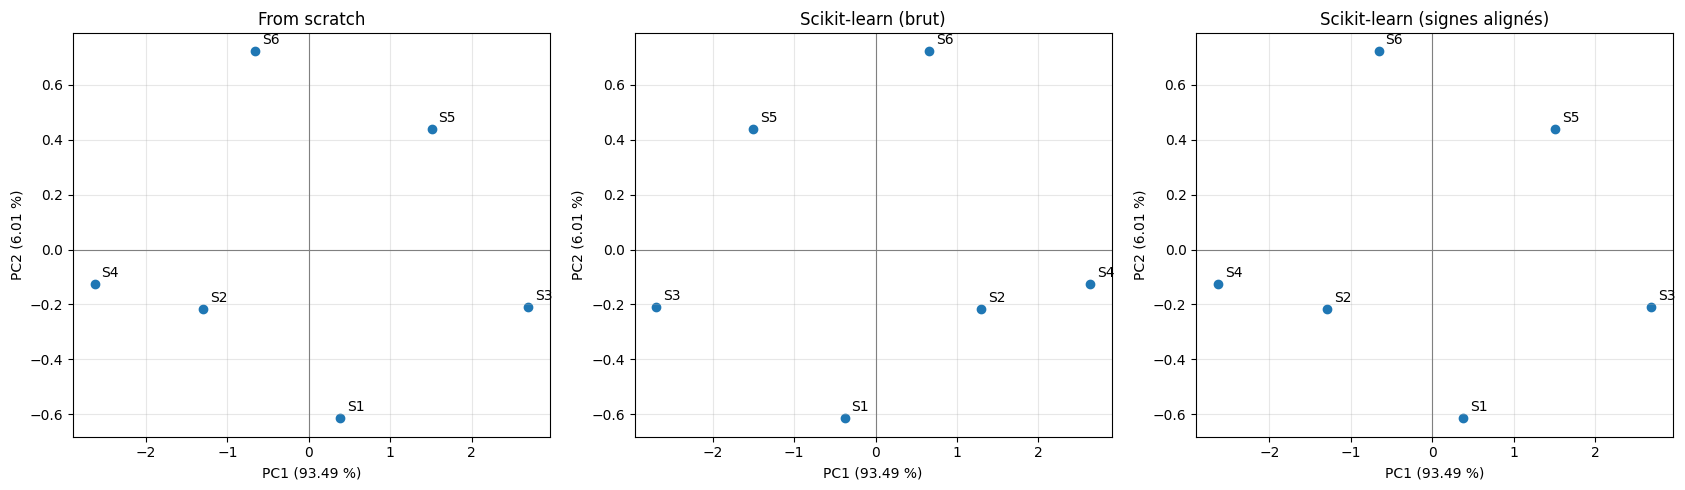

In [131]:
signs = np.sign((scores_scratch * scores_sk).sum(axis=0))
scores_sk_aligned = scores_sk * signs

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, sc, title in zip(
    axes,
    [scores_scratch, scores_sk, scores_sk_aligned],
    ["From scratch", "Scikit-learn (brut)", "Scikit-learn (signes alignés)"],
):
    ax.scatter(sc[:, 0], sc[:, 1], color="tab:blue")
    for i, name in enumerate(df.index):
        ax.annotate(name, (sc[i, 0], sc[i, 1]), xytext=(5, 5), textcoords="offset points")
    ax.axhline(0, color="gray", lw=0.8)
    ax.axvline(0, color="gray", lw=0.8)
    ax.set_xlabel(f"PC1 ({evr_scratch[0]*100:.2f} %)")
    ax.set_ylabel(f"PC2 ({evr_scratch[1]*100:.2f} %)")
    ax.set_title(title)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("pca_comparison.png", dpi=150)
plt.show()

### 17. Explication des différences (signes)

Un vecteur propre n'est défini qu'**au signe près** : si `v` est un vecteur propre, `-v` l'est aussi, avec la même valeur propre. NumPy (`eigh`, LAPACK) et scikit-learn (SVD) peuvent donc choisir des signes différents. Ici, **PC1 est inversée** entre les deux méthodes et PC2 est identique.

Cela correspond à une symétrie du nuage de points par rapport à un axe : les distances entre étudiants, les valeurs propres et les variances expliquées restent **identiques**. Les résultats sont donc équivalents.

### 18. Variance totale retenue par les 2 premières composantes

In [132]:
print(f"From scratch : {cum_scratch[1]*100:.2f} %")
print(f"Scikit-learn : {cum_sk[1]*100:.2f} %")

From scratch : 99.50 %
Scikit-learn : 99.50 %


## Interprétation des résultats

- Les quatre matières sont **très corrélées** (0,77 à 0,99) : une seule dimension résume presque toute l'information.
- **PC1 explique 93,49 %** de la variance. Tous ses coefficients ont le même signe (≈ 0,5) : c'est un axe de **niveau général**. S4 et S2 (meilleurs étudiants) sont à une extrémité, S3 et S5 (plus faibles) à l'autre.
- **PC2 explique 6,01 %** et oppose surtout Statistics à Programming.
- **PC1 + PC2 retiennent 99,50 %** de la variance totale : la réduction à 2 dimensions ne perd presque aucune information.
- Les deux implémentations donnent les mêmes valeurs propres, les mêmes ratios et les mêmes coordonnées au signe près.